# [Lab Session 2](otsu.ipynb)

In [21]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 2.1.]()** Implement Otsu thresholding as a re-usable function:

In [42]:

def otsu_thresholding(imgf):
    img8 = (imgf * 255).round().astype(np.uint8)
    h=np.zeros(256)
    for i in range(256):
        h[i]=np.sum(img8 == i)

    Otsu_values = []
    for T in range (img8.min()+1, img8.max()+1):
        class1_intensities = img8[img8 < T]
        class2_intensities = img8[img8 >= T]
        
        class1_bins = h[:T]
        class2_bins = h[T:]

        n1=np.sum(class1_bins)   #gesamtanzahl der pixel in dem bereich der bins
        n2=np.sum(class2_bins)

        var1= np.var(class1_intensities)
        var2 =np.var(class2_intensities)

        O = n1*var1+n2*var2
        Otsu_values.append(O)
        

    optimal_threshold= np.argmin(Otsu_values) + img8.min() +1

    return optimal_threshold
    


In [52]:
def otsu_perform(img8):
    new_img=img8.copy()
    for i in range(new_img.shape[0]):
        for j in range(new_img.shape[1]):
            pixel = new_img[i,j]
            if pixel > optimal_threshold:
                new_img[i,j] =255
            if pixel < optimal_threshold:
                new_img[i,j]=0
    return new_img


**[Task 2.2.]()** Implement a re-usable function to compute the Dice coefficient:

In [13]:
def compute_dice(bin1, bin2):
    assert bin1.dtype == bool
    assert bin2.dtype == bool
    
    up= (bin1*bin2).sum()*2
    down= bin1.sum()+bin2.sum()
    dice= up/down
    
    return dice

**[Task 2.3.]()** Test your implementations from above:

In [ ]:
img8 =plt.imread('data/NIH3T3/im/dna-0.png')

bin2 = plt.imread('data/NIH3T3/gt/0.png').astype(bool)  #groundtruth

optimal_threshold = otsu_thresholding(img8)
print(optimal_threshold)


31


31


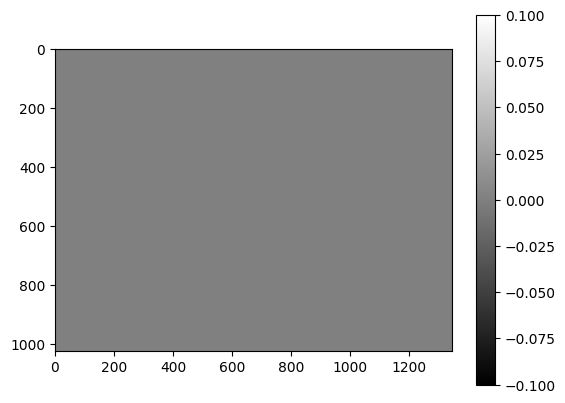

In [55]:
img8 =plt.imread('data/NIH3T3/im/dna-0.png')
optimal_threshold = otsu_thresholding(img8)
print(optimal_threshold)

new_img=img8.copy()
otsu_result =otsu_perform(new_img)
plt.imshow(otsu_result, 'grey')
plt.colorbar()



bin2 = plt.imread('data/NIH3T3/gt/0.png').astype(bool)  #groundtruth

The result should be the same as in your [otsu.ipynb](otsu.ipynb) notebook.

**[Task 2.4.]()** Perform batch processing: